# IndustReal: which parts can frozen C-RADIO tell apart (scratch)

## Section 1 - Purpose

A first look, before the classes to annotate are chosen: do the features of frozen C-RADIOv4 separate the small parts of IndustReal (washers, nuts, toothed washers) from each other and from the rest? The frames come from train, with every part loose on the desk (state 10000000000, before the first step), as in the first test on Mr Potato Head. Nothing here is a measure; the scratch only guides the choice of classes.

## Section 2 - Configuration

In [1]:
# 2.1 Configuration
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from remotezip import RemoteZip

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from perception.features import FeatureExtractor

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
DATA_DIR = PROJECT_ROOT / "data" / "industreal"
RECORDINGS_DIR = DATA_DIR / "recordings"
SHARPNESS_PATH = DATA_DIR / "train_box_sharpness.csv"           # sharpness of the usable train boxes (industreal_data, 8.3)
SCRATCH_DIR = DATA_DIR / "scratch_classes"                      # frames of this scratch (not tracked by git)
DATASET_URL = "https://data.4tu.nl/file/b008dd74-020d-4ea4-a8ba-7bb60769d224/"
TRAIN_ZIP_IDS = ["f58a5f18-9a71-4443-8a48-e59530df9ee8", "5aae5141-cece-41db-9681-47acd5300705",
                 "4e2ed830-a1fe-40fa-9c5a-2aeae3964616", "3ff5409e-165f-4354-9fa4-a4fde639a7a6"]   # train_p1 to train_p4
DEVICE, DTYPE = "cuda", torch.bfloat16
SEED = 0                                                        # draw of the recordings, fixed before looking
N_FRAMES = 3                                                    # enough for a first look; nothing is measured
print("Project folder:", PROJECT_ROOT, "| model found:", MODEL_DIR.is_dir())

Project folder: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project | model found: True


## Section 3 - Frames with every part loose

In [2]:
# 3.1 One frame per recording: the sharpest usable box before the first step, in 3 train assemblies drawn at random
assemblies = sorted(p.name for p in (RECORDINGS_DIR / "train").iterdir() if "_assy_" in p.name)
chosen = sorted(np.random.default_rng(SEED).choice(assemblies, N_FRAMES, replace=False))
sharp = pd.read_csv(SHARPNESS_PATH)

frames = []                                                     # (recording, jpg number, sharpness)
for rec in chosen:
    steps = [r for r in csv.reader(open(RECORDINGS_DIR / "train" / rec / "PSR_labels_with_errors.csv")) if r]
    first_step = min(int(r[0][:-4]) for r in steps)
    before = sharp[(sharp.recording == rec) & (sharp.frame < first_step)]   # state 10000000000 (industreal_data, 8.2)
    best = before.loc[before.sharpness.idxmax()]
    frames.append((rec, int(best.frame), round(float(best.sharpness), 1)))
print(len(assemblies), "train assemblies; chosen:", frames)

SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
todo = [(r, f) for r, f, _ in frames if not (SCRATCH_DIR / f"{r}_{f:06d}.jpg").exists()]
for file_id in TRAIN_ZIP_IDS:
    if not todo:
        break
    with RemoteZip(DATASET_URL + file_id) as z:
        names = set(z.namelist())
        for r, f in list(todo):
            if f"{r}/rgb/{f:06d}.jpg" in names:
                (SCRATCH_DIR / f"{r}_{f:06d}.jpg").write_bytes(z.read(f"{r}/rgb/{f:06d}.jpg"))
                todo.remove((r, f))
print("Missing after download:", todo)

20 train assemblies; chosen: [(np.str_('11_assy_0_1'), 161, 300.1), (np.str_('15_assy_0_1'), 9, 178.4), (np.str_('22_assy_0_1'), 17, 29.8)]
Missing after download: []


## Section 4 - Features

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Image: (1280, 720) | model input: (1280, 720) | patch grid (h, w, D): (45, 80, 1152)


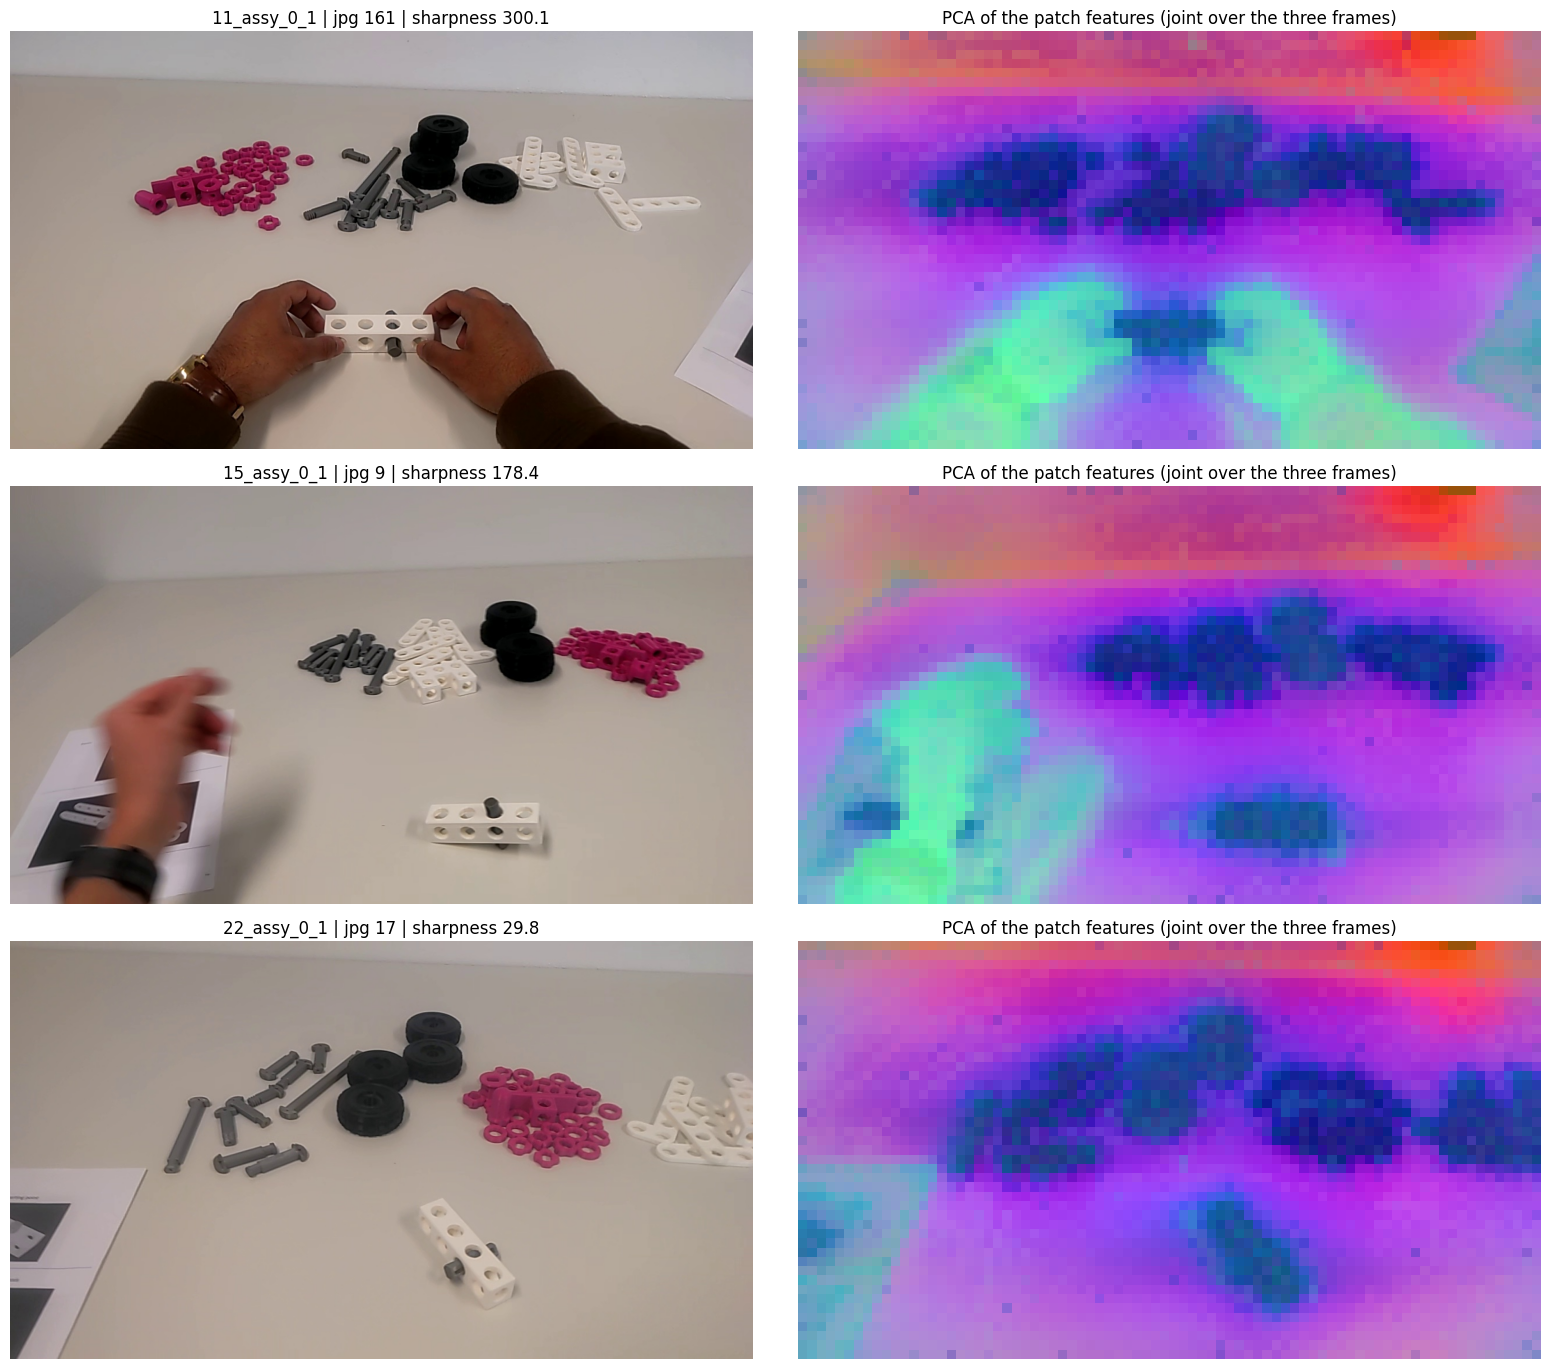

In [3]:
# 4.1 C-RADIOv4 features at the native size, and a PCA over the three frames together (3 components shown as RGB)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
images = [Image.open(SCRATCH_DIR / f"{r}_{f:06d}.jpg").convert("RGB") for r, f, _ in frames]
features = [extractor.extract(image) for image in images]       # (features, model input size) per frame
print("Image:", images[0].size, "| model input:", features[0][1], "| patch grid (h, w, D):", features[0][0].shape)

X = np.concatenate([f.reshape(-1, f.shape[-1]) for f, _ in features])
X = X / np.linalg.norm(X, axis=1, keepdims=True)                # unit vectors, as the prototypes use cosine similarity
Xc = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(Xc, full_matrices=False)
P = Xc @ Vt[:3].T
P = (P - P.min(axis=0)) / (P.max(axis=0) - P.min(axis=0))      # min-max per component, for display only

fig, axes = plt.subplots(N_FRAMES, 2, figsize=(16, 4.6 * N_FRAMES))
start = 0
for ax, image, (f, _), (rec, number, s) in zip(axes, images, features, frames):
    h, w, _ = f.shape
    ax[0].imshow(image)
    ax[0].set_title(f"{rec} | jpg {number} | sharpness {s}")
    ax[1].imshow(P[start:start + h * w].reshape(h, w, 3))
    ax[1].set_title("PCA of the patch features (joint over the three frames)")
    start += h * w
    for a in ax:
        a.axis("off")
plt.tight_layout()
plt.show()

Observation 4.1: The frames are 1280x720 and enter the model at their native size, as a grid of 45 x 80 patches with 1152 features each, so no resizing or cropping is needed for IndustReal. The three frames come from 11_assy_0_1 (jpg 161), 15_assy_0_1 (jpg 9) and 22_assy_0_1 (jpg 17).

In the first three components of the joint PCA the hands are green, the desk violet and the wall at the top red, while all the parts take the same dark blue: the pink washers and nuts, the grey pins, the black wheels, the white braces and the part held in the hand. The parts stand out from the desk as blobs, but these components do not separate the types of part.

The instruction sheet, in view in 15_assy_0_1 and 22_assy_0_1, takes its own light blue, and the parts printed on it take the same dark blue as the real parts. In these components a drawn part looks like a real one; whether this holds for the similarities used by the prototypes is checked with similarity maps. If it does, the sheet needs a class of its own, as the hands in Mr Potato Head, which were taken for arm_1 until they were annotated as a class.

The washers, nuts and toothed washers are pink and lie in one heap, since IndustReal sorts the parts into heaps by colour before each recording. At this distance a small part covers about one 16x16 patch, so a patch often holds more than one part (hypothesis, to be checked on the similarity maps).